# Modelo C4 de La Colmena

Este cuaderno presenta los niveles C1 Contexto, C2 Contenedores, C3 Componentes y C4 Código de la arquitectura actual. Los diagramas se dibujan como SVG desde celdas Python y no requieren paquetes gráficos ni recursos externos.

**Alcance:** monolito Python con interfaz HTML/JavaScript, API HTTP, SQLite y publicación asíncrona de CloudEvents a Apache Kafka. El pago es simulado dentro del proceso.

Los diagramas reflejan el estado as-is. En C3 se muestran explícitamente SQL directo desde app.py y el uso de una conexión SQLite en la Saga; por ello no se afirma que los Bounded Contexts ya tengan aislamiento técnico estricto.


## C1 — Contexto del sistema

Administradora, vendedor y cliente interactúan con La Colmena mediante la interfaz web. El sistema publica CloudEvents en Kafka. La pasarela de pago es actualmente un mock interno, por lo que no se representa como sistema externo.


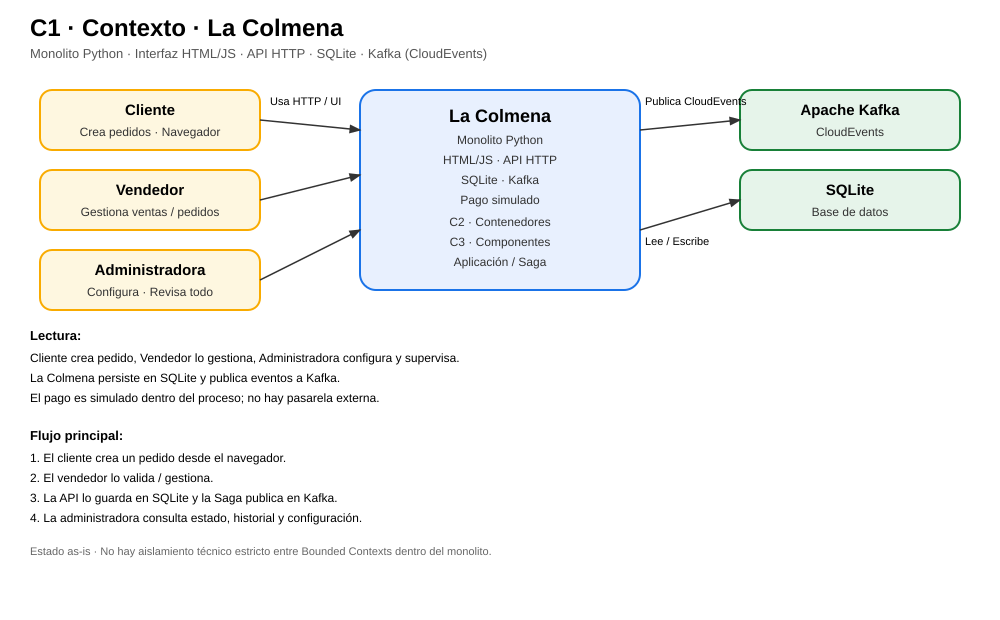

In [1]:
from IPython.display import SVG, display

svg_c1 = """
<svg xmlns="http://www.w3.org/2000/svg" width="1000" height="620" viewBox="0 0 1000 620" font-family="Arial, sans-serif">
  <defs><marker id="arr" markerWidth="8" markerHeight="8" refX="7" refY="3" orient="auto"><path d="M0,0 L0,6 L8,3 z" fill="#333"/></marker></defs>
  <rect width="1000" height="620" fill="white"/>
  <text x="30" y="36" font-size="24" font-weight="bold">C1 · Contexto · La Colmena</text>
  <text x="30" y="58" font-size="13" fill="#555">Monolito Python · Interfaz HTML/JS · API HTTP · SQLite · Kafka (CloudEvents)</text>
  <rect x="360" y="90" width="280" height="200" rx="16" fill="#e8f0fe" stroke="#1a73e8" stroke-width="2"/>
  <text x="500" y="122" font-size="18" font-weight="bold" text-anchor="middle">La Colmena</text>
  <text x="500" y="144" font-size="12" fill="#333" text-anchor="middle">Monolito Python</text>
  <text x="500" y="164" font-size="12" fill="#333" text-anchor="middle">HTML/JS · API HTTP</text>
  <text x="500" y="184" font-size="12" fill="#333" text-anchor="middle">SQLite · Kafka</text>
  <text x="500" y="204" font-size="12" fill="#333" text-anchor="middle">Pago simulado</text>
  <text x="500" y="226" font-size="12" fill="#333" text-anchor="middle">C2 · Contenedores</text>
  <text x="500" y="246" font-size="12" fill="#333" text-anchor="middle">C3 · Componentes</text>
  <text x="500" y="266" font-size="12" fill="#333" text-anchor="middle">Aplicación / Saga</text>
  <rect x="40" y="90" width="220" height="60" rx="12" fill="#fef7e0" stroke="#f9ab00" stroke-width="2"/>
  <text x="150" y="115" font-size="15" font-weight="bold" text-anchor="middle">Cliente</text>
  <text x="150" y="136" font-size="12" fill="#333" text-anchor="middle">Crea pedidos · Navegador</text>
  <rect x="40" y="170" width="220" height="60" rx="12" fill="#fef7e0" stroke="#f9ab00" stroke-width="2"/>
  <text x="150" y="195" font-size="15" font-weight="bold" text-anchor="middle">Vendedor</text>
  <text x="150" y="216" font-size="12" fill="#333" text-anchor="middle">Gestiona ventas / pedidos</text>
  <rect x="40" y="250" width="220" height="60" rx="12" fill="#fef7e0" stroke="#f9ab00" stroke-width="2"/>
  <text x="150" y="275" font-size="15" font-weight="bold" text-anchor="middle">Administradora</text>
  <text x="150" y="296" font-size="12" fill="#333" text-anchor="middle">Configura · Revisa todo</text>
  <rect x="740" y="90" width="220" height="60" rx="12" fill="#e6f4ea" stroke="#188038" stroke-width="2"/>
  <text x="850" y="115" font-size="15" font-weight="bold" text-anchor="middle">Apache Kafka</text>
  <text x="850" y="136" font-size="12" fill="#333" text-anchor="middle">CloudEvents</text>
  <rect x="740" y="170" width="220" height="60" rx="12" fill="#e6f4ea" stroke="#188038" stroke-width="2"/>
  <text x="850" y="195" font-size="15" font-weight="bold" text-anchor="middle">SQLite</text>
  <text x="850" y="216" font-size="12" fill="#333" text-anchor="middle">Base de datos</text>
  <line x1="260" y1="120" x2="360" y2="130" stroke="#333" stroke-width="1.5" marker-end="url(#arr)"/>
  <line x1="260" y1="200" x2="360" y2="175" stroke="#333" stroke-width="1.5" marker-end="url(#arr)"/>
  <line x1="260" y1="280" x2="360" y2="230" stroke="#333" stroke-width="1.5" marker-end="url(#arr)"/>
  <line x1="640" y1="130" x2="740" y2="120" stroke="#333" stroke-width="1.5" marker-end="url(#arr)"/>
  <line x1="640" y1="230" x2="740" y2="200" stroke="#333" stroke-width="1.5" marker-end="url(#arr)"/>
  <text x="270" y="105" font-size="11">Usa HTTP / UI</text>
  <text x="645" y="105" font-size="11">Publica CloudEvents</text>
  <text x="645" y="245" font-size="11">Lee / Escribe</text>
  <text x="30" y="340" font-size="13" font-weight="bold">Lectura:</text>
  <text x="30" y="362" font-size="12">Cliente crea pedido, Vendedor lo gestiona, Administradora configura y supervisa.</text>
  <text x="30" y="382" font-size="12">La Colmena persiste en SQLite y publica eventos a Kafka.</text>
  <text x="30" y="402" font-size="12">El pago es simulado dentro del proceso; no hay pasarela externa.</text>
  <text x="30" y="440" font-size="13" font-weight="bold">Flujo principal:</text>
  <text x="30" y="462" font-size="12">1. El cliente crea un pedido desde el navegador.</text>
  <text x="30" y="482" font-size="12">2. El vendedor lo valida / gestiona.</text>
  <text x="30" y="502" font-size="12">3. La API lo guarda en SQLite y la Saga publica en Kafka.</text>
  <text x="30" y="522" font-size="12">4. La administradora consulta estado, historial y configuración.</text>
  <text x="30" y="555" font-size="11" fill="#666">Estado as-is · No hay aislamiento técnico estricto entre Bounded Contexts dentro del monolito.</text>
</svg>
"""
display(SVG(svg_c1))

## C2 — Contenedores

La interfaz se ejecuta en el navegador; src/app.py sirve la API y coordina rutas/Saga en el proceso Python. SQLite es el almacenamiento local y el worker de outbox publica al broker Kafka.

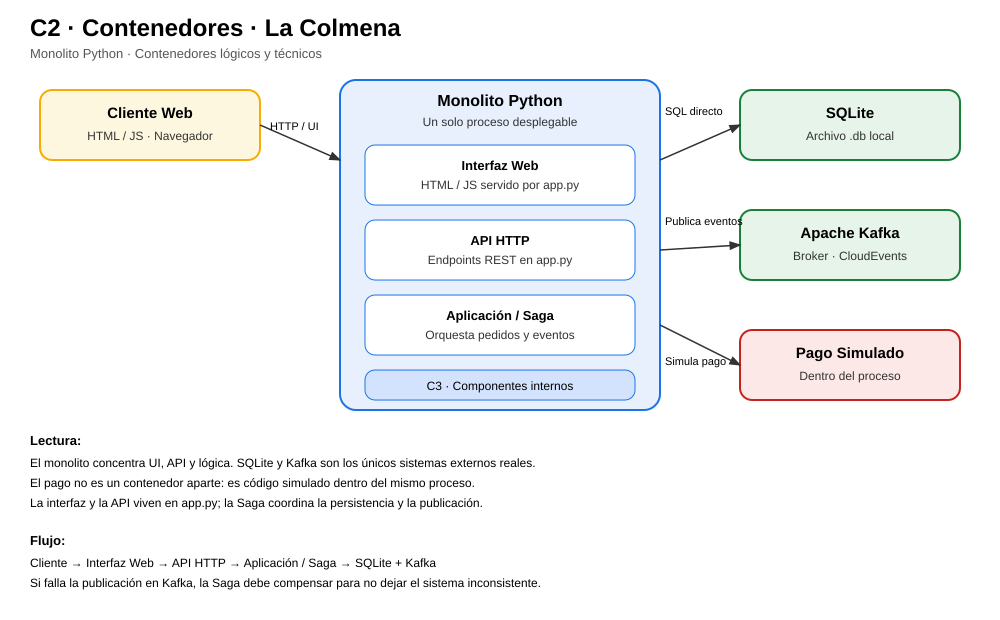

In [2]:
# to: app_settings
from IPython.display import SVG, display

svg_c2 = """
<svg xmlns="http://www.w3.org/2000/svg" width="1000" height="620" viewBox="0 0 1000 620" font-family="Arial, sans-serif">
  <defs><marker id="arr2" markerWidth="8" markerHeight="8" refX="7" refY="3" orient="auto"><path d="M0,0 L0,6 L8,3 z" fill="#333"/></marker></defs>
  <rect width="1000" height="620" fill="white"/>
  <text x="30" y="36" font-size="24" font-weight="bold">C2 · Contenedores · La Colmena</text>
  <text x="30" y="58" font-size="13" fill="#555">Monolito Python · Contenedores lógicos y técnicos</text>
  <rect x="40" y="90" width="220" height="70" rx="12" fill="#fef7e0" stroke="#f9ab00" stroke-width="2"/>
  <text x="150" y="118" font-size="15" font-weight="bold" text-anchor="middle">Cliente Web</text>
  <text x="150" y="140" font-size="12" fill="#333" text-anchor="middle">HTML / JS · Navegador</text>
  <rect x="340" y="80" width="320" height="330" rx="16" fill="#e8f0fe" stroke="#1a73e8" stroke-width="2"/>
  <text x="500" y="106" font-size="16" font-weight="bold" text-anchor="middle">Monolito Python</text>
  <text x="500" y="126" font-size="12" fill="#333" text-anchor="middle">Un solo proceso desplegable</text>
  <rect x="365" y="145" width="270" height="60" rx="10" fill="white" stroke="#1a73e8"/>
  <text x="500" y="170" font-size="13" font-weight="bold" text-anchor="middle">Interfaz Web</text>
  <text x="500" y="189" font-size="12" fill="#333" text-anchor="middle">HTML / JS servido por app.py</text>
  <rect x="365" y="220" width="270" height="60" rx="10" fill="white" stroke="#1a73e8"/>
  <text x="500" y="245" font-size="13" font-weight="bold" text-anchor="middle">API HTTP</text>
  <text x="500" y="264" font-size="12" fill="#333" text-anchor="middle">Endpoints REST en app.py</text>
  <rect x="365" y="295" width="270" height="60" rx="10" fill="white" stroke="#1a73e8"/>
  <text x="500" y="320" font-size="13" font-weight="bold" text-anchor="middle">Aplicación / Saga</text>
  <text x="500" y="339" font-size="12" fill="#333" text-anchor="middle">Orquesta pedidos y eventos</text>
  <rect x="365" y="370" width="270" height="30" rx="10" fill="#d3e3fd" stroke="#1a73e8"/>
  <text x="500" y="390" font-size="12" text-anchor="middle">C3 · Componentes internos</text>
  <rect x="740" y="90" width="220" height="70" rx="12" fill="#e6f4ea" stroke="#188038" stroke-width="2"/>
  <text x="850" y="118" font-size="15" font-weight="bold" text-anchor="middle">SQLite</text>
  <text x="850" y="140" font-size="12" fill="#333" text-anchor="middle">Archivo .db local</text>
  <rect x="740" y="210" width="220" height="70" rx="12" fill="#e6f4ea" stroke="#188038" stroke-width="2"/>
  <text x="850" y="238" font-size="15" font-weight="bold" text-anchor="middle">Apache Kafka</text>
  <text x="850" y="260" font-size="12" fill="#333" text-anchor="middle">Broker · CloudEvents</text>
  <rect x="740" y="330" width="220" height="70" rx="12" fill="#fce8e6" stroke="#c5221f" stroke-width="2"/>
  <text x="850" y="358" font-size="15" font-weight="bold" text-anchor="middle">Pago Simulado</text>
  <text x="850" y="380" font-size="12" fill="#333" text-anchor="middle">Dentro del proceso</text>
  <line x1="260" y1="125" x2="340" y2="160" stroke="#333" stroke-width="1.5" marker-end="url(#arr2)"/>
  <text x="270" y="130" font-size="11">HTTP / UI</text>
  <line x1="660" y1="160" x2="740" y2="125" stroke="#333" stroke-width="1.5" marker-end="url(#arr2)"/>
  <text x="665" y="115" font-size="11">SQL directo</text>
  <line x1="660" y1="250" x2="740" y2="245" stroke="#333" stroke-width="1.5" marker-end="url(#arr2)"/>
  <text x="665" y="225" font-size="11">Publica eventos</text>
  <line x1="660" y1="325" x2="740" y2="365" stroke="#333" stroke-width="1.5" marker-end="url(#arr2)"/>
  <text x="665" y="365" font-size="11">Simula pago</text>
  <text x="30" y="445" font-size="13" font-weight="bold">Lectura:</text>
  <text x="30" y="467" font-size="12">El monolito concentra UI, API y lógica. SQLite y Kafka son los únicos sistemas externos reales.</text>
  <text x="30" y="487" font-size="12">El pago no es un contenedor aparte: es código simulado dentro del mismo proceso.</text>
  <text x="30" y="507" font-size="12">La interfaz y la API viven en app.py; la Saga coordina la persistencia y la publicación.</text>
  <text x="30" y="545" font-size="13" font-weight="bold">Flujo:</text>
  <text x="30" y="567" font-size="12">Cliente → Interfaz Web → API HTTP → Aplicación / Saga → SQLite + Kafka</text>
  <text x="30" y="587" font-size="12">Si falla la publicación en Kafka, la Saga debe compensar para no dejar el sistema inconsistente.</text>
</svg>
"""
display(SVG(svg_c2))

## C3 — Componentes del contenedor Python

Los módulos reflejan las responsabilidades reales: adaptador HTTP (app.py), seguridad (auth.py), Saga (services.py), modelo/validadores, puertos, repositorios, eventos, outbox y logging. Las flechas rotuladas SQL directo y transacción SQLite son dependencias actuales que deben desaparecer para lograr límites estrictos entre contextos.

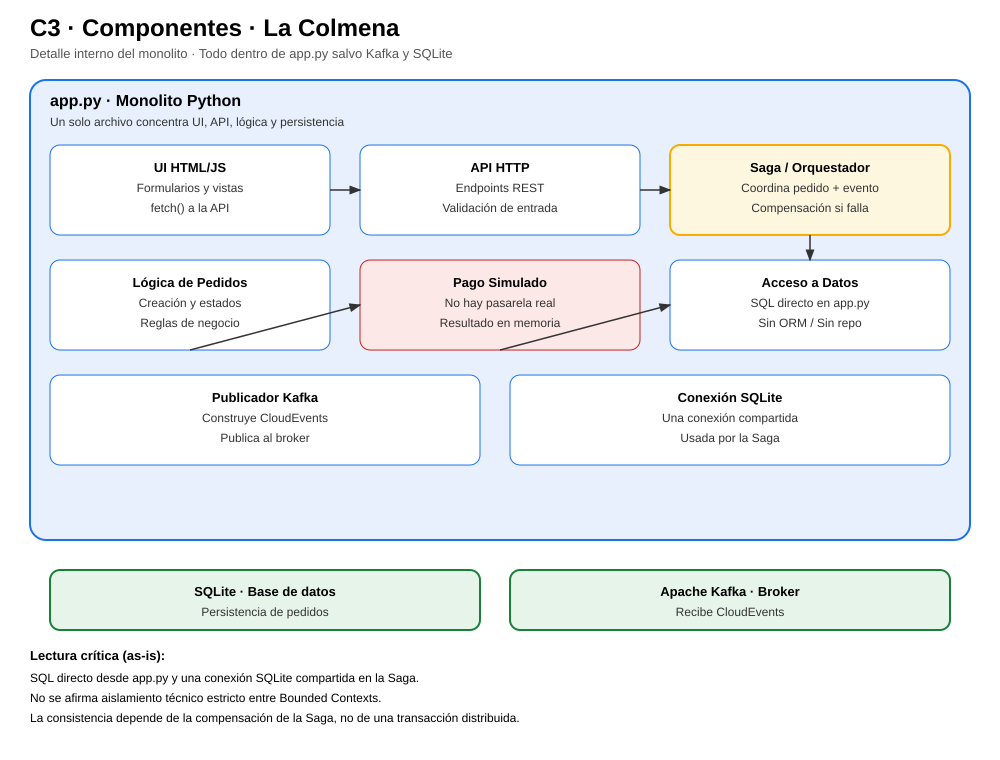

In [5]:
from IPython.display import SVG, display

svg_c3 = """
<svg xmlns="http://www.w3.org/2000/svg" width="1000" height="760" viewBox="0 0 1000 760" font-family="Arial, sans-serif">
  <defs><marker id="arr3" markerWidth="8" markerHeight="8" refX="7" refY="3" orient="auto"><path d="M0,0 L0,6 L8,3 z" fill="#333"/></marker></defs>
  <rect width="1000" height="760" fill="white"/>
  <text x="30" y="36" font-size="24" font-weight="bold">C3 · Componentes · La Colmena</text>
  <text x="30" y="58" font-size="13" fill="#555">Detalle interno del monolito · Todo dentro de app.py salvo Kafka y SQLite</text>
  <rect x="30" y="80" width="940" height="460" rx="16" fill="#e8f0fe" stroke="#1a73e8" stroke-width="2"/>
  <text x="50" y="106" font-size="16" font-weight="bold">app.py · Monolito Python</text>
  <text x="50" y="126" font-size="12" fill="#333">Un solo archivo concentra UI, API, lógica y persistencia</text>
  <rect x="50" y="145" width="280" height="90" rx="10" fill="white" stroke="#1a73e8"/>
  <text x="190" y="172" font-size="13" font-weight="bold" text-anchor="middle">UI HTML/JS</text>
  <text x="190" y="192" font-size="12" fill="#333" text-anchor="middle">Formularios y vistas</text>
  <text x="190" y="212" font-size="12" fill="#333" text-anchor="middle">fetch() a la API</text>
  <rect x="360" y="145" width="280" height="90" rx="10" fill="white" stroke="#1a73e8"/>
  <text x="500" y="172" font-size="13" font-weight="bold" text-anchor="middle">API HTTP</text>
  <text x="500" y="192" font-size="12" fill="#333" text-anchor="middle">Endpoints REST</text>
  <text x="500" y="212" font-size="12" fill="#333" text-anchor="middle">Validación de entrada</text>
  <rect x="670" y="145" width="280" height="90" rx="10" fill="#fef7e0" stroke="#f9ab00" stroke-width="2"/>
  <text x="810" y="172" font-size="13" font-weight="bold" text-anchor="middle">Saga / Orquestador</text>
  <text x="810" y="192" font-size="12" fill="#333" text-anchor="middle">Coordina pedido + evento</text>
  <text x="810" y="212" font-size="12" fill="#333" text-anchor="middle">Compensación si falla</text>
  <rect x="50" y="260" width="280" height="90" rx="10" fill="white" stroke="#1a73e8"/>
  <text x="190" y="287" font-size="13" font-weight="bold" text-anchor="middle">Lógica de Pedidos</text>
  <text x="190" y="307" font-size="12" fill="#333" text-anchor="middle">Creación y estados</text>
  <text x="190" y="327" font-size="12" fill="#333" text-anchor="middle">Reglas de negocio</text>
  <rect x="360" y="260" width="280" height="90" rx="10" fill="#fce8e6" stroke="#c5221f"/>
  <text x="500" y="287" font-size="13" font-weight="bold" text-anchor="middle">Pago Simulado</text>
  <text x="500" y="307" font-size="12" fill="#333" text-anchor="middle">No hay pasarela real</text>
  <text x="500" y="327" font-size="12" fill="#333" text-anchor="middle">Resultado en memoria</text>
  <rect x="670" y="260" width="280" height="90" rx="10" fill="white" stroke="#1a73e8"/>
  <text x="810" y="287" font-size="13" font-weight="bold" text-anchor="middle">Acceso a Datos</text>
  <text x="810" y="307" font-size="12" fill="#333" text-anchor="middle">SQL directo en app.py</text>
  <text x="810" y="327" font-size="12" fill="#333" text-anchor="middle">Sin ORM / Sin repo</text>
  <rect x="50" y="375" width="430" height="90" rx="10" fill="white" stroke="#1a73e8"/>
  <text x="265" y="402" font-size="13" font-weight="bold" text-anchor="middle">Publicador Kafka</text>
  <text x="265" y="422" font-size="12" fill="#333" text-anchor="middle">Construye CloudEvents</text>
  <text x="265" y="442" font-size="12" fill="#333" text-anchor="middle">Publica al broker</text>
  <rect x="510" y="375" width="440" height="90" rx="10" fill="white" stroke="#1a73e8"/>
  <text x="730" y="402" font-size="13" font-weight="bold" text-anchor="middle">Conexión SQLite</text>
  <text x="730" y="422" font-size="12" fill="#333" text-anchor="middle">Una conexión compartida</text>
  <text x="730" y="442" font-size="12" fill="#333" text-anchor="middle">Usada por la Saga</text>
  <line x1="330" y1="190" x2="360" y2="190" stroke="#333" stroke-width="1.5" marker-end="url(#arr3)"/>
  <line x1="640" y1="190" x2="670" y2="190" stroke="#333" stroke-width="1.5" marker-end="url(#arr3)"/>
  <line x1="810" y1="235" x2="810" y2="260" stroke="#333" stroke-width="1.5" marker-end="url(#arr3)"/>
  <line x1="190" y1="350" x2="360" y2="305" stroke="#333" stroke-width="1.5" marker-end="url(#arr3)"/>
  <line x1="500" y1="350" x2="670" y2="305" stroke="#333" stroke-width="1.5" marker-end="url(#arr3)"/>
  <rect x="50" y="570" width="430" height="60" rx="10" fill="#e6f4ea" stroke="#188038" stroke-width="2"/>
  <text x="265" y="596" font-size="13" font-weight="bold" text-anchor="middle">SQLite · Base de datos</text>
  <text x="265" y="616" font-size="12" fill="#333" text-anchor="middle">Persistencia de pedidos</text>
  <rect x="510" y="570" width="440" height="60" rx="10" fill="#e6f4ea" stroke="#188038" stroke-width="2"/>
  <text x="730" y="596" font-size="13" font-weight="bold" text-anchor="middle">Apache Kafka · Broker</text>
  <text x="730" y="616" font-size="12" fill="#333" text-anchor="middle">Recibe CloudEvents</text>
  <text x="30" y="660" font-size="13" font-weight="bold">Lectura crítica (as-is):</text>
  <text x="30" y="682" font-size="12">SQL directo desde app.py y una conexión SQLite compartida en la Saga.</text>
  <text x="30" y="702" font-size="12">No se afirma aislamiento técnico estricto entre Bounded Contexts.</text>
  <text x="30" y="722" font-size="12">La consistencia depende de la compensación de la Saga, no de una transacción distribuida.</text>
</svg>
"""
display(SVG(svg_c3))

## C4 — Código (detalle de la Saga)

Este nivel muestra cómo hoy una sola función en services.py toca 3 tablas en una misma transacción SQLite. Es la evidencia del acoplamiento que impide Bounded Contexts estrictos.


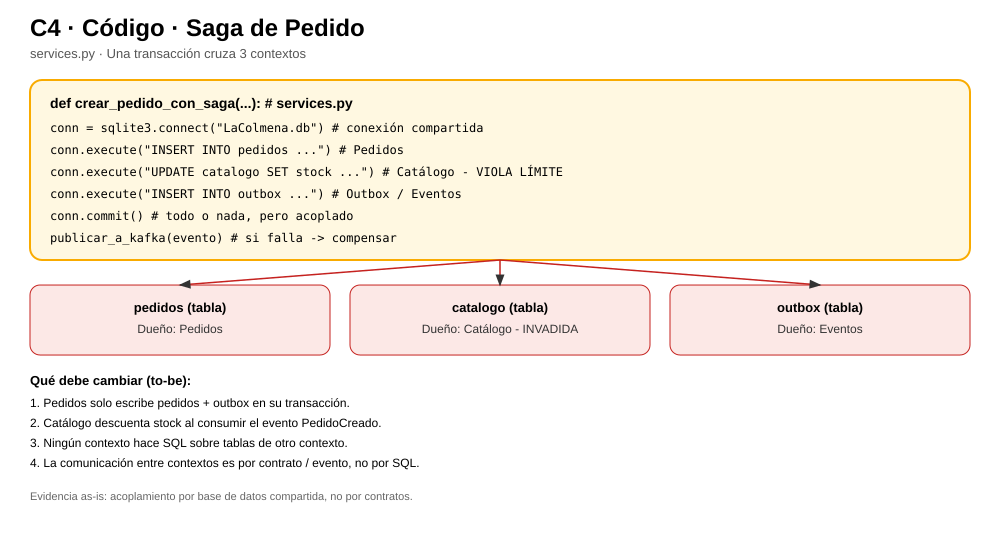

In [7]:
from IPython.display import SVG, display

svg_c4 = """
<svg xmlns="http://www.w3.org/2000/svg" width="1000" height="560" viewBox="0 0 1000 560" font-family="Arial, sans-serif">
  <defs><marker id="arr4" markerWidth="8" markerHeight="8" refX="7" refY="3" orient="auto"><path d="M0,0 L0,6 L8,3 z" fill="#333"/></marker></defs>
  <rect width="1000" height="560" fill="white"/>
  <text x="30" y="36" font-size="24" font-weight="bold">C4 · Código · Saga de Pedido</text>
  <text x="30" y="58" font-size="13" fill="#555">services.py · Una transacción cruza 3 contextos</text>
  <rect x="30" y="80" width="940" height="180" rx="12" fill="#fff8e1" stroke="#f9ab00" stroke-width="2"/>
  <text x="50" y="108" font-size="14" font-weight="bold">def crear_pedido_con_saga(...):  # services.py</text>
  <text x="50" y="132" font-size="12" font-family="monospace">conn = sqlite3.connect("LaColmena.db")  # conexión compartida</text>
  <text x="50" y="154" font-size="12" font-family="monospace">conn.execute("INSERT INTO pedidos ...")   # Pedidos</text>
  <text x="50" y="176" font-size="12" font-family="monospace">conn.execute("UPDATE catalogo SET stock ...") # Catálogo - VIOLA LÍMITE</text>
  <text x="50" y="198" font-size="12" font-family="monospace">conn.execute("INSERT INTO outbox ...")    # Outbox / Eventos</text>
  <text x="50" y="220" font-size="12" font-family="monospace">conn.commit()  # todo o nada, pero acoplado</text>
  <text x="50" y="242" font-size="12" font-family="monospace">publicar_a_kafka(evento)  # si falla -&gt; compensar</text>
  <rect x="30" y="285" width="300" height="70" rx="10" fill="#fce8e6" stroke="#c5221f"/>
  <text x="180" y="312" font-size="13" font-weight="bold" text-anchor="middle">pedidos (tabla)</text>
  <text x="180" y="333" font-size="12" fill="#333" text-anchor="middle">Dueño: Pedidos</text>
  <rect x="350" y="285" width="300" height="70" rx="10" fill="#fce8e6" stroke="#c5221f"/>
  <text x="500" y="312" font-size="13" font-weight="bold" text-anchor="middle">catalogo (tabla)</text>
  <text x="500" y="333" font-size="12" fill="#333" text-anchor="middle">Dueño: Catálogo - INVADIDA</text>
  <rect x="670" y="285" width="300" height="70" rx="10" fill="#fce8e6" stroke="#c5221f"/>
  <text x="820" y="312" font-size="13" font-weight="bold" text-anchor="middle">outbox (tabla)</text>
  <text x="820" y="333" font-size="12" fill="#333" text-anchor="middle">Dueño: Eventos</text>
  <line x1="500" y1="260" x2="180" y2="285" stroke="#c5221f" stroke-width="1.5" marker-end="url(#arr4)"/>
  <line x1="500" y1="260" x2="500" y2="285" stroke="#c5221f" stroke-width="1.5" marker-end="url(#arr4)"/>
  <line x1="500" y1="260" x2="820" y2="285" stroke="#c5221f" stroke-width="1.5" marker-end="url(#arr4)"/>
  <text x="30" y="385" font-size="13" font-weight="bold">Qué debe cambiar (to-be):</text>
  <text x="30" y="407" font-size="12">1. Pedidos solo escribe pedidos + outbox en su transacción.</text>
  <text x="30" y="427" font-size="12">2. Catálogo descuenta stock al consumir el evento PedidoCreado.</text>
  <text x="30" y="447" font-size="12">3. Ningún contexto hace SQL sobre tablas de otro contexto.</text>
  <text x="30" y="467" font-size="12">4. La comunicación entre contextos es por contrato / evento, no por SQL.</text>
  <text x="30" y="500" font-size="11" fill="#666">Evidencia as-is: acoplamiento por base de datos compartida, no por contratos.</text>
</svg>
"""
display(SVG(svg_c4))

## Lectura del modelo y brechas

- **C1:** muestra usuarios y el broker externo, no detalles internos de despliegue.
- **C2:** el cliente web, el proceso Python, SQLite y Kafka son los contenedores principales.
- **C3:** las rutas HTTP todavía acceden directamente a varias tablas; `services.py` también administra una transacción SQLite que cruza pedido, catálogo y outbox.
- Para completar Bounded Contexts estrictos, cada contexto debe ser el único propietario de sus tablas; las llamadas entre contextos deben pasar por contratos y eventos, no por SQL compartido. Ver el [documento D2](../docs/D2_MODELADO_C4_ISO25010_BOUNDED_CONTEXTS.md) para el mapa de propiedad, métricas Ca/Ce/I/D y criterios ISO 25010.


In [8]:
## D2 — Mapa de propiedad y métricas (resumen)

| Contexto | Tablas que DEBE poseer | Hoy invade |
| --- | --- | --- |
| Pedidos | pedidos, pedidos_items | outbox, catalogo |
| Catálogo | catalogo, productos | - |
| Eventos / Outbox | outbox, eventos | - |
| Pagos (mock) | pagos_simulados | - |

**Métricas:**
- **Ca (Aferente):** cuántos dependen de mí. Alto = difícil de cambiar.
- **Ce (Eferente):** de cuántos dependo yo. Alto = frágil.
- **I = Ce / (Ca + Ce):** Inestabilidad. Cerca de 1 = inestable.
- **D = |A + I - 1|:** Distancia de la secuencia principal. Cerca de 0 = ideal.

**Objetivo to-be:** app.py con Ce bajo, cada contexto con I bajo y D cercano a 0, y 0 invasiones de tablas.

**ISO 25010:**
- Mantenibilidad: separar repositorios por contexto.
- Fiabilidad: Saga con compensación + outbox.
- Seguridad: auth.py centraliza roles Administradora / Vendedor / Cliente.

SyntaxError: invalid syntax (2122376697.py, line 3)